# Interprétation et analyse des erreurs

Ce notebook ouvre la boîte noire des deux modèles retenus, soit le gradient boosting qui **estime** le
délai (médiane) et celui qui **promet** une date (quantile 0,963). Il répond à trois questions :
- quelles informations le modèle utilise-t-il ?
- où se trompe-t-il le plus ?
- quand et où la promesse échoue-t-elle ?

Toutes les analyses portent sur les **mois de validation** (novembre 2017 à avril 2018), avec le
protocole habituel c'est-à-dire un modèle réentraîné chaque mois sur les commandes déjà livrées. Les mois de test
ne sont pas réutilisés, ils ont servi une seule fois à l'évaluation finale.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import partial_dependence, permutation_importance
from sklearn.metrics import mean_absolute_error

from olist_promesse.donnees import charger_commandes, selectionner_commandes
from olist_promesse.evaluation import (
    CIBLE,
    MOIS_VALIDATION,
    date_livraison,
    date_promise,
    decoupage_mensuel,
    en_retard,
    predire_par_mois,
    resumer_promesse,
)
from olist_promesse.modeles import modele_gradient_boosting, modele_promesse
from olist_promesse.variables import COLONNES_BRUTES

BLEU, VERT, GRIS = "#2a78d6", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "grid.color": "#e5e4e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.labelcolor": GRIS,
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "axes.titlelocation": "left",
})

commandes, _ = selectionner_commandes(charger_commandes())
REGIONS = {
    "Nord": ["AC", "AM", "AP", "PA", "RO", "RR", "TO"],
    "Nordeste": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Centre-Ouest": ["DF", "GO", "MS", "MT"],
    "Sudeste": ["ES", "MG", "RJ", "SP"],
    "Sud": ["PR", "RS", "SC"],
}
region_du_client = (
    commandes["customer_state"]
    .map({etat: region for region, etats in REGIONS.items() for etat in etats})
    .rename("région du client")
)

## 1. Les informations qui comptent

L'**importance par permutation** mesure ce que le modèle perd quand on brouille une variable. Pour comprendre son fonctionnement, on
mélange ses valeurs entre les commandes évaluées pour rompre sa relation avec la cible et on regarde de combien la MAE augmente. Une
variable inutile ne coûte alors rien et une variable dont le modèle dépend fait grimper l'erreur.

Mais attention, brouiller une variable seule sous-estime l'importance des variables corrélées. La distance, le fait
d'être dans le même État et les États se remplacent en partie l'un l'autre. En brouiller une permet toujours au modèle de retrouver en partie l'information qu'elle contient chez les autres. On brouille donc aussi
les variables par groupe, en mélangeant ensemble toutes les variables d'un groupe.

Le calcul est refait pour chacun des 6 mois de validation, avec le modèle entraîné pour ce mois.

In [2]:
GROUPES = {
    "géographie": ["distance_km", "meme_etat", "customer_state", "seller_state"],
    "vendeur": ["seller_id"],
    "commande": ["prix_total", "fret_total", "poids_total_g", "volume_total_cm3", "n_articles", "categorie_principale"],
    "paiement": ["type_paiement_principal", "n_echeances"],
    "calendrier": ["jour_semaine_achat"],
}


def importance_par_groupe(modele, X, y, groupes, n_repetitions=5):
    """Hausse moyenne de la MAE quand on mélange ensemble toutes les variables d'un groupe."""
    generateur = np.random.default_rng(0)
    reference = mean_absolute_error(y, modele.predict(X))
    hausses = {}
    for nom, colonnes in groupes.items():
        essais = []
        for _ in range(n_repetitions):
            melange = X.copy()
            melange[colonnes] = X[colonnes].to_numpy()[generateur.permutation(len(X))]
            essais.append(mean_absolute_error(y, modele.predict(melange)) - reference)
        hausses[nom] = np.mean(essais)
    return pd.Series(hausses)


par_variable, par_groupe, historique_vendeur = {}, {}, []
for mois in MOIS_VALIDATION:
    entrainement, evaluation = decoupage_mensuel(commandes, mois)
    modele = modele_gradient_boosting().fit(entrainement[COLONNES_BRUTES], entrainement[CIBLE])
    X = modele.named_steps["preparation"].transform(evaluation[COLONNES_BRUTES])
    estimateur = modele.named_steps["modele"]
    permutation = permutation_importance(estimateur, X, evaluation[CIBLE], scoring="neg_mean_absolute_error",
                                         n_repeats=5, random_state=0)
    par_variable[str(mois)] = pd.Series(permutation.importances_mean, index=X.columns)
    par_groupe[str(mois)] = importance_par_groupe(estimateur, X, evaluation[CIBLE], GROUPES)
    # Nombre de commandes d'entraînement du vendeur, utile à la section 3.
    historique_vendeur.append(evaluation["seller_id"].map(entrainement["seller_id"].value_counts()).fillna(0))

par_variable = pd.DataFrame(par_variable)
par_groupe = pd.DataFrame(par_groupe)
historique_vendeur = pd.concat(historique_vendeur)
display(par_groupe.mean(axis=1).sort_values(ascending=False).round(3).rename("hausse de la MAE (j)"))

géographie    1.634
vendeur       0.239
commande      0.130
calendrier    0.045
paiement      0.026
Name: hausse de la MAE (j), dtype: float64

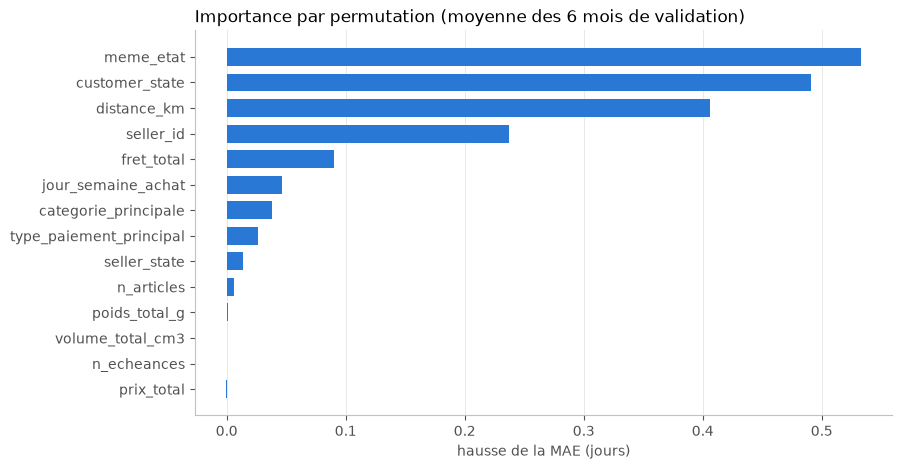

In [3]:
importance = par_variable.mean(axis=1).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importance.index, importance.values, color=BLEU, height=0.7)
ax.grid(axis="y", visible=False)
ax.set(title="Importance par permutation (moyenne des 6 mois de validation)", xlabel="hausse de la MAE (jours)")
plt.show()

On remarque que **la géographie porte l'essentiel du signal**. Brouiller ensemble la distance, l'indicateur « même
État » et les deux États fait perdre **1,6 jour** de MAE. Variable par variable, l'indicateur « même
État » (0,53 jour), l'État du client (0,49) et la distance (0,41) arrivent en tête. On constate leur corrélation grâce à leur somme
(1,4 jour) qui reste inférieure à l'effet du groupe. Quand une seule est brouillée, les autres la
suppléent en partie.

Viennent ensuite le vendeur (0,24 jour), puis les caractéristiques de la commande (0,13 jour,
surtout les frais de port), le jour de la semaine (0,05) et le moyen de paiement (0,03).

**Cinq variables n'apportent rien** : le prix, le poids, le volume, le nombre d'articles et le nombre
d'échéances (moins de 0,01 jour). Elles pourraient être retirées pour simplifier l'API. On ne le fait
pas ici.

## 2. L'effet de la distance

La **dépendance partielle** montre comment la prédiction varie avec une variable, les autres restant
telles qu'elles sont. Pour cela, on attribue la même distance à toutes les commandes d'avril 2018, on prédit,
puis on fait la moyenne, et ainsi de suite pour chaque distance de la grille. On compare le modèle
d'estimation et celui de la promesse, entraînés pour avril.

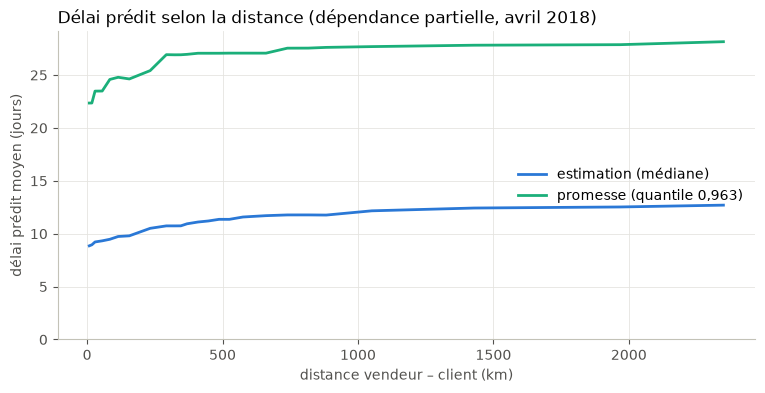

,estimation (médiane),"promesse (quantile 0,963)",marge
8.151159,8.9,22.4,13.5
83.772156,9.5,24.6,15.1
292.427500,10.7,26.9,16.2
409.429499,11.1,27.1,16.0
575.307501,11.6,27.1,15.5
882.707324,11.8,27.6,15.9
2349.122524,12.7,28.2,15.4


In [4]:
entrainement, evaluation = decoupage_mensuel(commandes, pd.Period("2018-04", freq="M"))
dependance = {}
for nom, modele in {"estimation (médiane)": modele_gradient_boosting(), "promesse (quantile 0,963)": modele_promesse()}.items():
    modele.fit(entrainement[COLONNES_BRUTES], entrainement[CIBLE])
    X = modele.named_steps["preparation"].transform(evaluation[COLONNES_BRUTES])
    grille = np.quantile(X["distance_km"].dropna(), np.linspace(0.02, 0.98, 25))
    resultat = partial_dependence(modele.named_steps["modele"], X, ["distance_km"],
                                  custom_values={"distance_km": grille}, kind="average", method="brute")
    dependance[nom] = pd.Series(resultat["average"][0], index=resultat["grid_values"][0])
dependance = pd.DataFrame(dependance)

fig, ax = plt.subplots()
for (nom, valeurs), couleur in zip(dependance.items(), [BLEU, VERT]):
    ax.plot(valeurs.index, valeurs.values, color=couleur, lw=2, label=nom)
ax.legend(frameon=False, loc="center right")
ax.set(title="Délai prédit selon la distance (dépendance partielle, avril 2018)",
       xlabel="distance vendeur – client (km)", ylabel="délai prédit moyen (jours)", ylim=(0, None))
plt.show()
dependance.assign(marge=dependance.iloc[:, 1] - dependance.iloc[:, 0]).iloc[::4].round(1)

Toutes choses égales par ailleurs, l'estimation passe de **8,9 jours à 12,7 jours** entre 8 km et
2 350 km, et l'essentiel de la hausse se joue sur les 300 premiers kilomètres. L'effet propre de la distance paraît modéré parce que les autres variables géographiques,
inchangées, en portent une partie : la dépendance partielle isole mal les variables corrélées.

La promesse suit la même pente, avec une **marge de 13 à 16 jours** au-dessus de l'estimation, même
pour une commande à quelques kilomètres. C'est le prix du quantile 0,963 : couvrir 96 % des cas
impose de se protéger contre la longue queue des délais, qui existe partout, y compris pour les
commandes locales.

## 3. Où le modèle d'estimation se trompe

In [5]:
estimation = predire_par_mois(modele_gradient_boosting(), commandes, MOIS_VALIDATION, COLONNES_BRUTES)
evaluees = commandes.loc[estimation.index]
erreur = estimation - evaluees[CIBLE]


def erreurs_par(segment):
    """Part des commandes, MAE et erreur médiane (positive : délai surestimé) pour chaque segment."""
    return pd.DataFrame({
        "commandes (%)": 100 * segment.value_counts(normalize=True),
        "délai médian (j)": evaluees[CIBLE].groupby(segment).median(),
        "MAE (j)": erreur.abs().groupby(segment).mean(),
        "erreur médiane (j)": erreur.groupby(segment).median(),
    }).round(2)


lents = evaluees[CIBLE] >= evaluees[CIBLE].quantile(0.9)
print(f"Part de l'erreur totale due aux 10 % de délais les plus longs : {erreur.abs()[lents].sum() / erreur.abs().sum():.1%}")
erreurs_par(pd.qcut(evaluees[CIBLE], [0, 0.25, 0.5, 0.75, 0.9, 1]).rename("délai réel"))

Part de l'erreur totale due aux 10 % de délais les plus longs : 40.3%


,commandes (%),délai médian (j),MAE (j),erreur médiane (j)
délai réel,,,,
"(0.985, 7.816]",25.0,5.28,2.53,1.94
"(7.816, 12.306]",25.0,10.00,2.34,0.10
"(12.306, 19.107]",25.0,15.10,4.05,-3.43
"(19.107, 28.021]",15.0,22.40,9.48,-9.42
"(28.021, 208.352]",10.0,35.20,24.63,-21.48


On voit bien que **l'erreur se concentre dans la queue** avec les 10 % de commandes les plus lentes (au-delà de 28 jours)
portant **40 % de l'erreur totale**. Le modèle les sous-estime de 21 jours en médiane. Ces délais correspondent certainement aux incidents classiques (colis perdu, retard du transporteur, pic d'activité) qu'aucune information disponible à
l'achat ne permet de prévoir. À l'inverse, les commandes les plus rapides sont surestimées d'environ
2 jours. Le modèle vise un délai typique, et ne peut pas distinguer d'avance une livraison
particulièrement rapide.

In [6]:
display(erreurs_par(pd.cut(historique_vendeur.loc[evaluees.index], [-1, 0, 9, 99, np.inf],
                           labels=["inédit", "1 à 9", "10 à 99", "100 et plus"]).rename("commandes passées du vendeur")))
erreurs_par(region_du_client.loc[evaluees.index])

,commandes (%),délai médian (j),MAE (j),erreur médiane (j)
commandes passées du vendeur,,,,
inédit,6.86,11.81,6.24,-1.04
1 à 9,14.09,12.40,6.73,-1.97
10 à 99,38.37,12.09,5.96,-1.29
100 et plus,40.68,12.80,6.03,-1.67


,commandes (%),délai médian (j),MAE (j),erreur médiane (j)
région du client,,,,
Centre-Ouest,6.03,15.94,6.15,-2.26
Nord,1.74,25.70,10.40,-6.72
Nordeste,9.20,20.19,8.40,-2.92
Sud,14.38,14.57,6.61,-2.05
Sudeste,68.66,10.33,5.59,-1.21


**Selon le vendeur**, l'erreur varie peu avec 6,0 jours pour les vendeurs établis et 6,2 pour les vendeurs
inédits (7 % des commandes), qui reçoivent le délai moyen faute d'historique. Le segment le plus
difficile est celui des vendeurs de **1 à 9 commandes** (6,7 jours). Leur historique est trop court
pour être fiable, mais assez long pour peser dans l'encodage.

**Selon la région**, l'erreur suit la longueur des délais. 5,6 jours dans le Sudeste (69 % des
commandes, délai médian de 10 jours), contre 8,4 dans le Nordeste et 10,4 dans le Nord (délai médian
de 26 jours). Rapportée au délai médian de la région, l'erreur va pourtant de 39 % (Centre-Ouest)
à 54 % (Sudeste). En proportion, ce sont donc les délais courts qui sont les plus difficiles à prédire.

## 4. Quand la promesse échoue

In [7]:
promesse = predire_par_mois(modele_promesse(), commandes, MOIS_VALIDATION, COLONNES_BRUTES)
retard = en_retard(commandes, promesse)
jour_livraison = date_livraison(evaluees).dt.round("s").dt.normalize()
depassement = (jour_livraison - date_promise(evaluees["order_purchase_timestamp"], promesse)).dt.days[retard]

print(f"Commandes en retard : {retard.sum()} ({retard.mean():.2%})")
print(f"Retards de plus de 7 jours : {(depassement > 7).mean():.1%} des retards")
depassement.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1).rename("jours de retard")

Commandes en retard : 4304 (10.84%)
Retards de plus de 7 jours : 45.5% des retards


count    4304.0
mean       10.1
std        12.2
min         1.0
25%         3.0
50%         7.0
75%        13.0
90%        22.0
max       180.0
Name: jours de retard, dtype: float64

Sur les mois de validation, 4 304 commandes (10,8 %) arrivent après le jour promis. Quand la promesse
échoue, elle échoue nettement : **7 jours de retard en médiane**, et près de la moitié des retards
(45 %) dépassent une semaine. Ce ne sont pas des retards d'un jour, que l'on corrigerait avec un peu
plus de marge, mais réellement des incidents.

In [8]:
semaine = evaluees["order_purchase_timestamp"].dt.to_period("W").dt.start_time.rename("semaine d'achat")
par_semaine = pd.DataFrame({"commandes": retard.groupby(semaine).size(), "taux de retard (%)": 100 * retard.groupby(semaine).mean()})
display(par_semaine.sort_values("taux de retard (%)", ascending=False).head(6).round(1))

retards_par_vendeur = retard.groupby(evaluees["seller_id"]).agg(["sum", "size"]).sort_values("sum", ascending=False)
print(f"Vendeurs ayant au moins un retard : {(retards_par_vendeur['sum'] > 0).sum()} sur {len(retards_par_vendeur)}")
print(f"Les 10 vendeurs qui cumulent le plus de retards : {retards_par_vendeur['sum'].head(10).sum() / retard.sum():.1%} "
      f"des retards, pour {retards_par_vendeur['size'].head(10).sum() / len(evaluees):.1%} des commandes")

,commandes,taux de retard (%)
semaine d'achat,,
2018-02-26,1832,20.3
2017-12-04,1612,19.7
2017-11-27,2021,19.1
2017-11-20,2882,18.8
2018-03-05,1584,16.4
2018-02-19,1701,14.9


Vendeurs ayant au moins un retard : 872 sur 1771
Les 10 vendeurs qui cumulent le plus de retards : 17.5% des retards, pour 16.8% des commandes


**Les retards se concentrent dans le temps, pas chez quelques vendeurs.** Les semaines les plus
touchées sont celles du Black Friday et des semaines suivantes (19 à 20 % de retard fin novembre et
début décembre 2017), puis la fin février et le début mars 2018 (15 à 20 %). À l'inverse, les 10
vendeurs qui cumulent le plus de retards en portent 17,5 %, pour 16,8 % des commandes (exactement
leur part d'activité). Exclure des vendeurs ne réduirait donc pas les retards, c'est surtout la période qui
compte.

In [9]:
par_region = pd.concat({
    "promesse du modèle": promesse.groupby(region_du_client.loc[promesse.index]).apply(lambda p: resumer_promesse(commandes, p)).unstack(),
    "promesse Olist": evaluees["promesse_jours"].groupby(region_du_client.loc[promesse.index]).apply(lambda p: resumer_promesse(commandes, p)).unstack(),
}, axis=1)
par_region.round(2)

promesse du modèle                            promesse Olist  \
                 taux de retard (%) délai promis moyen (j) taux de retard (%)   
région du client                                                                
Centre-Ouest                  11.57                  26.18              10.74   
Nord                          22.06                  34.82              15.97   
Nordeste                      11.06                  34.91              19.57   
Sud                           12.12                  26.11              10.14   
Sudeste                       10.19                  21.38               9.56   

                                         
                 délai promis moyen (j)  
région du client                         
Centre-Ouest                      26.79  
Nord                              39.02  
Nordeste                          29.83  
Sud                               27.50  
Sudeste                           22.33

**Selon la région, le modèle et Olist ne répartissent pas leur marge de la même façon**, pour un taux
de retard global équivalent :
- dans le Nordeste, le modèle promet 5 jours de plus qu'Olist (34,9 contre 29,8 jours) et divise
  presque le retard par deux (11,1 % contre 19,6 %)
- dans le Nord, il promet 4 jours de moins (34,8 contre 39,0) et y est en retard plus souvent
  (22,1 % contre 16,0 %) ;
- dans le Sudeste, le Sud et le Centre-Ouest, les deux sont proches.

Un quantile unique ne garantit donc pas la même fiabilité à tous les clients. Pour notre modèle, le Nord, avec peu de
commandes (2 %) et des délais très dispersés, est le moins bien servi. En production, il serait possible de fixer le quantile par région et le valider avec les équipes métier.

## Synthèse

1. **Le modèle s'appuie surtout sur la géographie** (1,6 jour de MAE en jeu), puis sur le vendeur
   (0,24 jour). Le prix, le poids, le volume, le nombre d'articles et le nombre d'échéances
   n'apportent rien (ils seraient à retirer lors d'une prochaine version, après validation sur de
   nouvelles données).
2. **La distance allonge l'estimation de 9 à 13 jours**, et la promesse garde une marge de 13 à
   16 jours partout, même pour les commandes locales, à cause de la longue queue des délais.
3. **Les erreurs viennent des incidents**, les 10 % de commandes les plus lentes portent 40 % de
   l'erreur et la moitié des promesses manquées le sont de plus d'une semaine.
4. **Les retards sont concentrés dans le temps** (Black Friday, fin février 2018), pas chez certains
   vendeurs. On retrouve la dérive déjà mesurée précédemment.
5. **La fiabilité n'est pas uniforme entre régions** avec notamment le Nord qui subit 22 % de retard avec le quantile
   unique. Un quantile par région serait une piste d'amélioration.